In [3]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
(x_train, y_train),(x_test,y_test)  =keras.datasets.mnist.load_data()


In [5]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

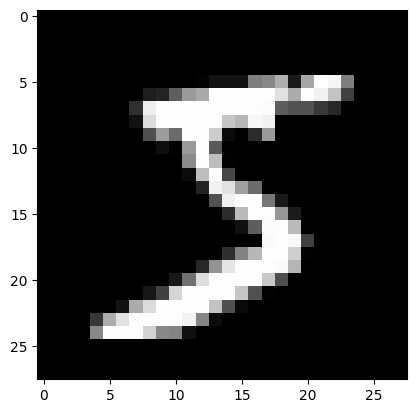

In [6]:
plt.imshow(x_train[0],cmap="gray")

input to model:
- 28x28
- grayscale images


In [7]:

print("Original train img: ", x_train.shape)
print("Original test img: ", x_test.shape)

Original train img:  (60000, 28, 28)
Original test img:  (10000, 28, 28)


1) train dataset: the model learns and update weight

epochs: عدد مرات عمل backpropg
طيب مش احنا بكل مرة بنعمل backprog
بيتحدث W
وبطلع loss جديد

2) Validation dataset: Check how the model works during training

3) test dataset: we check final perfomance after tarining

100 epoch
يعني المودل هيشتغل 100 مرة

في كل مرة من ال 100
بختبر المودل على داتا ال Validation وبطلعلي loss

وبالنهاية بس اخلص ال 100 هروح اختبره على داتا test

In [8]:
# 75 train (60000 -5000) ,5% validate(5000) , 20% test (10000 sample)

x_train_f=x_train[:-5000]
y_train_f=y_train[:-5000]

x_validate=x_train[-5000:]
y_validate=y_train[-5000:]

x_train = x_train_f
y_train = y_train_f

In [9]:

print("train img: ", x_train.shape)
print("val img: ", x_validate.shape)
print("test img: ", x_test.shape)


train img:  (55000, 28, 28)
val img:  (5000, 28, 28)
test img:  (10000, 28, 28)


In [10]:
# Normalize the Pixel Values

x_train = x_train / 255.0
x_validate = x_validate / 255.0
x_test = x_test / 255.0

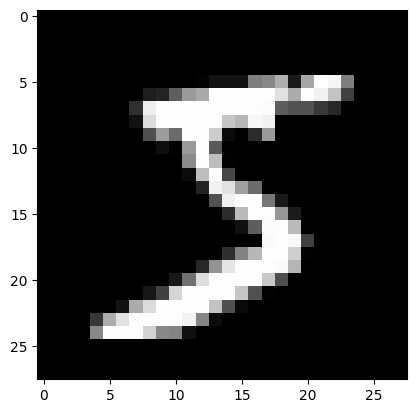

In [11]:
plt.imshow(x_train[0],cmap="gray")

In [12]:
print(y_train[0])

5


In [13]:
y_train

array([5, 0, 4, ..., 0, 4, 0], shape=(55000,), dtype=uint8)

In [14]:
classes = np.unique(y_train)
classes

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [15]:
len(classes)

# output layers لازم تعطيني 10احتمالات
# انو الرقم الي بالصورة اي واحد من ال 10#

10

In [16]:
# 1) bulid model
model = keras.Sequential(
    [
        #1) input layer
        keras.Input(shape=(28,28)),
        keras.layers.Flatten(),
        #2) hidden layers
                      #Dense(num_of_Neuron , activation_function )
        keras.layers.Dense(16, activation="relu"),  # HL1

        #3) output layer (Dense عادي ولكن الاخيرة )
              # num_of_Neuron = num of classes
         keras.layers.Dense(10,activation="softmax"), #softmax give you ten porb.

    ]


)

1. Num of layers

اختارهم بناءا على تعقيد الصور الي داخلة ع المودل كيف يعني ؟؟

- لو الصورة بسيطة و gray scale
  - ابدا ب 1 layer واحسب النتائج وبعدين زيد الثانية لو محتاج

- لو الصور RGB ابدا من 2 layers واختبر وبعدين زود لو النتيجة مش نافعة

2. num_of_Neuron
  - first layer start with 16
  - next layers 16 >> 32 >> 64 >> 64 >> 128



In [17]:
# 2) compile model

# :بقول فيها للمودل
# شو طريقة تحديث الاوزان
# وكيف يحسب ال loss
# وشو مقياس الدقة

model.compile(
  optimizer="adam", # weight-update methods (adam, sgd, rmsporp)
  loss="sparse_categorical_crossentropy",
  metrics=["accuracy"]

)

In [18]:
# 3) train model

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_data=(x_validate,y_validate)
)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8751 - loss: 0.4458 - val_accuracy: 0.9302 - val_loss: 0.2431
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9208 - loss: 0.2770 - val_accuracy: 0.9424 - val_loss: 0.2031
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9314 - loss: 0.2423 - val_accuracy: 0.9458 - val_loss: 0.1902
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9374 - loss: 0.2174 - val_accuracy: 0.9516 - val_loss: 0.1752
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9425 - loss: 0.1993 - val_accuracy: 0.9522 - val_loss: 0.1641
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9465 - loss: 0.1837 - val_accuracy: 0.9562 - val_loss: 0.1624
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9493 - loss: 0.1723 - val_accuracy: 0.9570 - val_loss: 0.1589
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9528 - loss: 0.1627 - 

In [19]:
test_loss , test_acc = model.evaluate(x_test,y_test)
print("test_acc: ", test_acc)
print("test_loss: ", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9472 - loss: 0.1849  
test_acc:  0.9472000002861023
test_loss:  0.18485358357429504


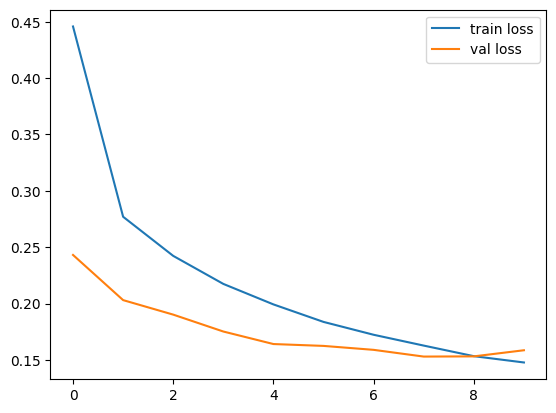

In [20]:
# plot history
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.show()

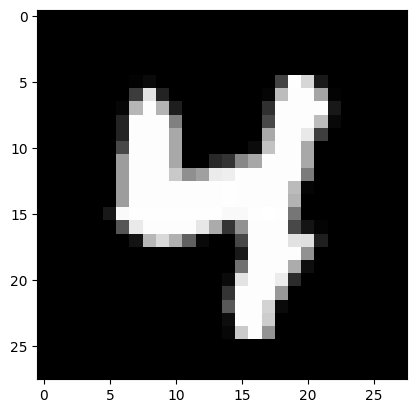

In [21]:
plt.imshow(x_test[85],cmap='gray')

In [22]:
x_test[85].shape

(28, 28)

In [23]:
x_test[85].reshape(1,28,28).shape

(1, 28, 28)

In [24]:
ten_porb = model.predict(x_test[85].reshape(1,28,28))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


In [25]:
ten_porb

array([[1.0578160e-10, 1.6981983e-15, 8.4292584e-10, 2.3582627e-08,
        9.9996948e-01, 1.8839374e-07, 3.6325203e-11, 9.1150187e-06,
        4.3354885e-07, 2.0661706e-05]], dtype=float32)

In [26]:
print("Actual label:", y_test[85])
print("Pred label:" ,np.argmax(ten_porb)) # index to high prob

Actual label: 4
Pred label: 4


# اي صورة بدي ادخلها ع المودل يتوقعها لازم تكون عبارة عن:

## 1: 28*28  (resize to 28*28)
## 2: gray (cov to grayscale)
## 3: norm

# after that enter the new img to model

# Tasks:


### **Task 1 — Deep Prediction Analysis**
Select **three samples** from `x_test` and:

1. Run `model.predict(...)` on each sample.  
2. Print the **Predicted Label** and **True Label**.  



In [27]:
print(x_test[980])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.16078431 0.43921569 0.90588235 1.         0.99607843
  0.9960784


---

### **Task 2 — Custom Image Generalization Test**
- Create a handwritten digit using a drawing tool (الرسام تبع الجهاز تبعك)
- preprocessing (
  - check background is black , and number is White.
  - grayscale
  - resizing to 28×28
  - normalization
  - reshape(1,28,28)
)

- run model and get prediction

- Then analyze:

  - Did the model correctly classify the digit?  
  - If not, why? Consider distribution shift, noise, or lack of augmentation.  
  - How does this relate to representation learning in neural networks?

---

In [28]:
from skimage import io, data, color


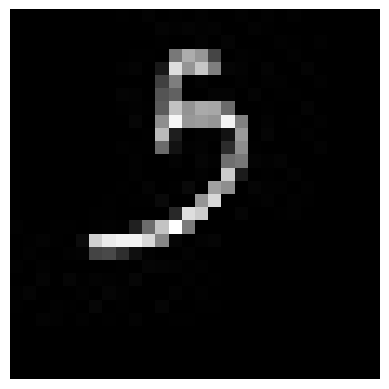

In [29]:
myimage = io.imread('Untitled (1).jpg')
plt.figure()
plt.imshow(myimage, cmap='gray')
plt.axis('off')
plt.show()

In [39]:
Myimage_pred = model.predict(myimage.reshape(1,28,28))
Myimage_true = 5

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


In [41]:
print("Pred label:" ,np.argmax(Myimage_pred)) 
print("True label:" ,Myimage_true) 

Pred label: 2
True label: 5


## the model failed to predict the number correctly, i would assume due to resizing the image from a large dimensions generated noise and pixelation 

# Next lec:

- types of activation functions (relu,----)
- types of Optimizer methods (adam, ---)
- contorl num of epochs (How to stop model if have overfitting)
  - EarlyStopping

- هنكتشف شو في مشاكل بالمودل الي بنيناه ونشوف كيف هنحل المشكلة هاي بخوازمية اخر ى
زي مثلا CNN
